# 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import ast

# 2. Membaca Dataset

In [2]:
df = pd.read_csv("../data/processed/comments_clean.csv")
df_token = pd.read_csv("../data/processed/comments_tokenized.csv")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

display(df.head())
display(df_token.head())

,comment_id,user_id,date,comment_text,likes,shares,replies,text_clean
0,C0001,eva45t.86,2026-11-12 17:27:34,Semua egois hanya mikirin kepentingan sendiri 😭,0,0,0,semua egois hanya pikir kepentingan sendiri
1,C0002,fitri.fiy_,2026-11-12 17:20:58,Setujuuu… ▓,0,0,0,setuju
2,C0003,santiartiyani,2026-11-12 17:20:50,Setuju. inti nya mereka itu gk ada satu pun yg...,0,0,0,setuju inti nya mereka itu tidak ada satu pun ...
3,C0004,allofkidz,2026-11-12 17:14:34,VIRDIAN SI PALING PAKAR 🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣🤣,0,0,0,virdian si paling pakar
4,C0005,putraforsaken,2026-11-12 17:09:11,Ending story anak haram konstitusi. Waktu bapa...,3,0,0,ending story anak haram konstitusi waktu bapak...


,comment_id,tokens,text_processed
0,C0001,"[""egois"", ""pikir""]",egois pikir
1,C0002,"[""tuju""]",tuju
2,C0003,"[""tuju"", ""inti"", ""peduli"", ""rakyat"", ""perut"", ...",tuju inti peduli rakyat perut golong ketawa ha...
3,C0004,"[""pakar""]",pakar
4,C0005,"[""anak"", ""haram"", ""konstitusi"", ""kuasa"", ""umur...",anak haram konstitusi kuasa umur wapres ubah a...


# 3. Memahami Struktur dan Kualitas Data

In [3]:
# Dimensi data
print("Dimensi data:", df.shape)

# Informasi tipe data dan kolom
df.info()

# Statistik deskriptif
display(df.describe(include="all"))

# Missing value
print("\nMissing Value:")
display(df.isna().sum())

# Data duplikat
print("\nDuplikasi comment_id:", df["comment_id"].duplicated().sum())

# Rentang tanggal
print("\nPeriode data:")
print(df["date"].min(), "sampai", df["date"].max())

Dimensi data: (11017, 8)
<class 'pandas.DataFrame'>
RangeIndex: 11017 entries, 0 to 11016
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   comment_id    11017 non-null  str           
 1   user_id       11017 non-null  str           
 2   date          11017 non-null  datetime64[us]
 3   comment_text  11017 non-null  str           
 4   likes         11017 non-null  int64         
 5   shares        11017 non-null  int64         
 6   replies       11017 non-null  int64         
 7   text_clean    10983 non-null  str           
dtypes: datetime64[us](1), int64(3), str(4)
memory usage: 3.1 MB


,comment_id,user_id,date,comment_text,likes,shares,replies,text_clean
count,11017,11017,11017,11017,11017.000000,11017.0,11017.000000,10983
unique,11017,8485,NaN,10760,NaN,NaN,NaN,10398
top,C0001,brianoargantara,NaN,Up,NaN,NaN,NaN,up
freq,1,94,NaN,72,NaN,NaN,NaN,140
mean,NaN,NaN,2026-10-15 16:52:14.946809,NaN,285.708541,0.0,8.915857,NaN
min,NaN,NaN,2026-08-13 14:11:56,NaN,0.000000,0.0,0.000000,NaN
25%,NaN,NaN,2026-10-12 23:53:10,NaN,0.000000,0.0,0.000000,NaN
50%,NaN,NaN,2026-10-19 17:28:07,NaN,1.000000,0.0,0.000000,NaN
75%,NaN,NaN,2026-10-31 19:12:46,NaN,4.000000,0.0,1.000000,NaN
max,NaN,NaN,2026-11-12 17:27:34,NaN,149178.000000,0.0,7253.000000,NaN



Missing Value:


comment_id       0
user_id          0
date             0
comment_text     0
likes            0
shares           0
replies          0
text_clean      34
dtype: int64


Duplikasi comment_id: 0

Periode data:
2026-08-13 14:11:56 sampai 2026-11-12 17:27:34


# 4. Analisis Engagement

In [4]:
# Statistik engagement
engagement = df[["likes", "shares", "replies"]].agg(
    ["mean", "median", "max", "sum"]
).T

engagement.columns = ["Rata-rata", "Median", "Maksimum", "Total"]

display(engagement)

,Rata-rata,Median,Maksimum,Total
likes,285.708541,1.0,149178.0,3147651.0
shares,0.000000,0.0,0.0,0.0
replies,8.915857,0.0,7253.0,98226.0


# 5. Analisis Aktivitas Komentar Berdasarkan Waktu

In [5]:
# Membuat variabel waktu
df["tanggal"] = df["date"].dt.date
df["hari"] = df["date"].dt.dayofweek
df["jam"] = df["date"].dt.hour

# Menghitung jumlah komentar per hari
daily_comments = df.groupby("tanggal").size().reset_index(name="jumlah_komentar")

display(daily_comments.head())

C:\Users\najwe\AppData\Local\Temp\ipykernel_10112\3092622829.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["hari"] = df["date"].dt.dayofweek


,tanggal,jumlah_komentar
0,2026-08-13,2
1,2026-08-14,9
2,2026-08-15,8
3,2026-08-19,65
4,2026-08-20,84


In [6]:
fig = px.line(
    daily_comments,
    x="tanggal",
    y="jumlah_komentar",
    title="Jumlah Komentar per Hari",
    labels={
        "tanggal": "Tanggal",
        "jumlah_komentar": "Jumlah Komentar"
    }
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Tanggal",
    yaxis_title="Jumlah Komentar"
)

fig.show()

In [7]:
# Membuat nama hari
hari_mapping = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu"
}

df["nama_hari"] = df["hari"].map(hari_mapping)

# Menghitung jumlah komentar berdasarkan hari dan jam
heatmap_data = df.pivot_table(
    index="nama_hari",
    columns="jam",
    values="comment_id",
    aggfunc="count",
    fill_value=0
)

# Mengurutkan hari
urutan_hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
heatmap_data = heatmap_data.reindex(urutan_hari)

display(heatmap_data)

jam,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
nama_hari,,,,,,,,,,,,,,,,,,,,,
Senin,41,20,14,19,16,62,57,78,60,44,...,67,97,77,107,126,110,86,79,94,48
Selasa,43,32,20,9,21,31,48,82,106,105,...,63,71,100,78,72,76,85,98,90,71
Rabu,40,26,12,8,12,29,60,91,74,73,...,92,156,78,67,116,104,92,124,88,68
Kamis,42,18,20,17,20,54,71,87,79,87,...,81,96,90,65,75,62,67,75,96,92
Jumat,59,42,31,19,20,47,54,55,88,113,...,89,68,65,70,81,66,52,65,62,43
Sabtu,26,5,4,10,7,25,32,28,36,59,...,63,57,52,41,82,83,92,85,64,76
Minggu,60,40,26,14,17,31,33,64,91,93,...,55,36,49,77,71,59,62,57,94,59


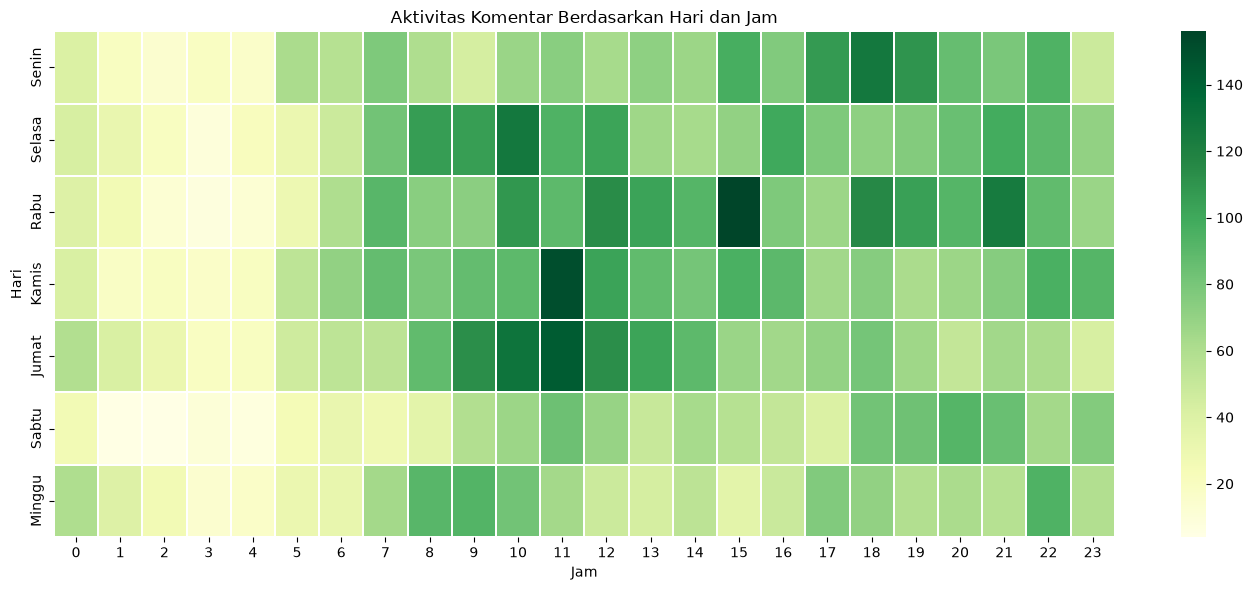

In [8]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlGn",
    linewidths=0.3,
    annot=False
)

plt.title("Aktivitas Komentar Berdasarkan Hari dan Jam")
plt.xlabel("Jam")
plt.ylabel("Hari")
plt.tight_layout()
plt.show()

# 6. Analisis Panjang Komentar

In [9]:
# Menghitung jumlah kata pada setiap komentar
df["jumlah_kata"] = df["text_clean"].fillna("").apply(
    lambda x: len(x.split())
)

# Ringkasan statistik panjang komentar
display(df["jumlah_kata"].describe())

count    11017.000000
mean        16.282654
std         16.121272
min          0.000000
25%          5.000000
50%         11.000000
75%         21.000000
max        132.000000
Name: jumlah_kata, dtype: float64

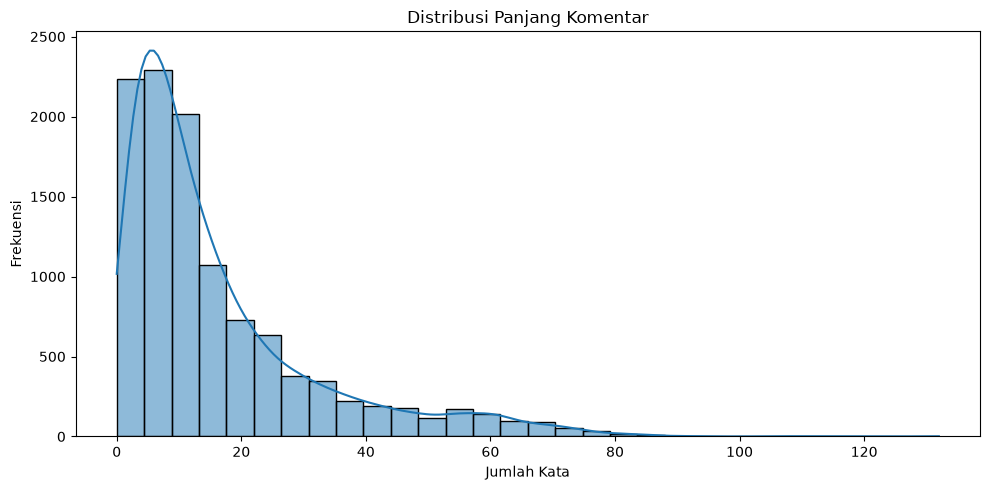

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["jumlah_kata"],
    bins=30,
    kde=True
)

plt.title("Distribusi Panjang Komentar")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

In [11]:
# Menghitung panjang komentar yang tidak kosong
df["jumlah_kata"] = df["text_clean"].apply(
    lambda x: len(x.split()) if pd.notna(x) and x.strip() else np.nan
)

display(df["jumlah_kata"].describe())

count    10983.000000
mean        16.333060
std         16.120691
min          1.000000
25%          5.000000
50%         11.000000
75%         21.000000
max        132.000000
Name: jumlah_kata, dtype: float64

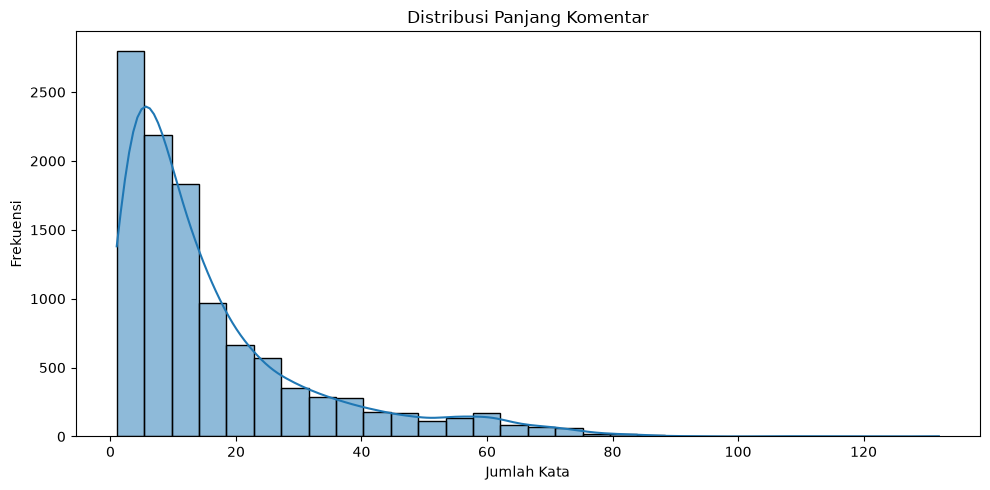

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["jumlah_kata"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribusi Panjang Komentar")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# 7. Analisis Frekuensi Kata dan Wordcloud

In [26]:
custom_stopwords = {
    "karhutla", "bakar", "kalimantan", "hutan", "lahan"
}

from collections import Counter

all_tokens = []

for tokens in df_token["tokens"].dropna():
    token_list = ast.literal_eval(tokens)
    filtered_tokens = [
        word for word in token_list
        if word not in custom_stopwords
    ]
    all_tokens.extend(filtered_tokens)

word_freq = Counter(all_tokens)

top_words = pd.DataFrame(
    word_freq.most_common(20),
    columns=["kata", "frekuensi"]
)

display(top_words)

,kata,frekuensi
0,allah,750
1,asap,707
2,perintah,653
3,indonesia,557
4,api,535
5,padam,516
6,papua,503
7,sawit,498
8,bantu,451
9,hujan,432


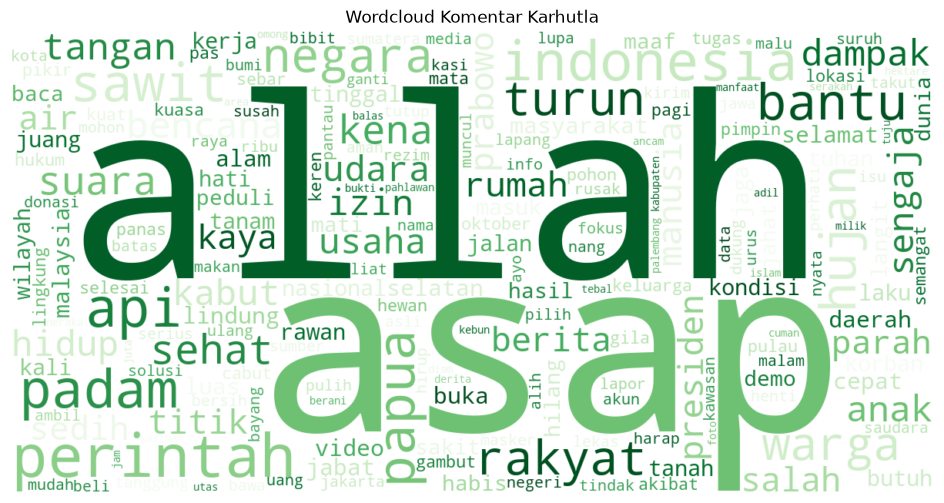

In [28]:
from wordcloud import WordCloud

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="Greens"
).generate_from_frequencies(word_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Wordcloud Komentar Karhutla")
plt.show()

In [29]:

print("JUMLAH DATA")
print(f"Total komentar: {len(df)}")
print(f"Komentar dengan teks bersih: {df['text_clean'].notna().sum()}")

print("\nRATA-RATA ENGAGEMENT")
display(df[["likes", "shares", "replies"]].mean().round(2))

print("\nAKTIVITAS KOMENTAR")
print(f"Tanggal dengan komentar terbanyak: {daily_comments.loc[daily_comments['jumlah_komentar'].idxmax(), 'tanggal']}")
print(f"Jumlah komentar terbanyak: {daily_comments['jumlah_komentar'].max()}")

print("\nPANJANG KOMENTAR")
display(df["jumlah_kata"].describe().round(2))

print("\n20 KATA TERATAS")
display(top_words)

JUMLAH DATA
Total komentar: 11017
Komentar dengan teks bersih: 10983

RATA-RATA ENGAGEMENT


likes      285.71
shares       0.00
replies      8.92
dtype: float64


AKTIVITAS KOMENTAR
Tanggal dengan komentar terbanyak: 2026-10-16
Jumlah komentar terbanyak: 637

PANJANG KOMENTAR


count    10983.00
mean        16.33
std         16.12
min          1.00
25%          5.00
50%         11.00
75%         21.00
max        132.00
Name: jumlah_kata, dtype: float64


20 KATA TERATAS


,kata,frekuensi
0,allah,750
1,asap,707
2,perintah,653
3,indonesia,557
4,api,535
5,padam,516
6,papua,503
7,sawit,498
8,bantu,451
9,hujan,432
